# ModernBERT for Named Entity Recognition in Heliophysics Literature

Token-classification pipeline (ModernBERT-base) for five entity types in solar-physics papers: `Instrument`, `Mission`, `TimeRange`, `SpatialRegion`, `DatasetReference`.

**Pipeline:** Label Studio export -> data preparation (sliding windows) -> ModernBERT fine-tuning -> evaluation with seqeval.

**Notes**
- Designed to run on Google Colab (GPU). The annotated corpus is not included here.
- Training uses 1,024-token windows (stride 128) to fit on a single Colab GPU, even though ModernBERT supports up to 8,192 tokens.
- Test macro F1 (seqeval, entity level): 0.682.


## 1. Install dependencies

In [ ]:
!pip install transformers datasets seqeval matplotlib scikit-learn torch --quiet


##2. Set up the output folder


In [ ]:
import os
from pathlib import Path

# Where all intermediate files, plots and reports are written.
# (On Colab you can point this to Google Drive after running: from google.colab import drive; drive.mount("/content/drive"))
OUTPUT_FOLDER = Path("outputs")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
os.environ["OUTPUT_FOLDER"] = str(OUTPUT_FOLDER)  # so !python ... "$OUTPUT_FOLDER" works below
print("Output folder:", OUTPUT_FOLDER)


## 3. Upload the Label Studio export

In [ ]:
from google.colab import files
import shutil

# The annotated corpus (Label Studio JSON export) is not included in this repository.
# Upload your own export here; it is expected to be saved as entities_export.json.
uploaded = files.upload()
uploaded_name = next(iter(uploaded))
shutil.move(uploaded_name, OUTPUT_FOLDER / "entities_export.json")
print("Saved to:", OUTPUT_FOLDER / "entities_export.json")


## 4. Write the pipeline scripts

### `visualize_entities_dataset.py`

In [ ]:
%%writefile visualize_entities_dataset.py

import sys
import json
from pathlib import Path
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np

ENTITY_TYPES = ["Instrument", "Mission", "TimeRange", "SpatialRegion", "DatasetReference"]
COLORS = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]


def load_reviewed_examples(path):
    with open(path, encoding="utf-8") as f:
        tasks = json.load(f)

    examples = []
    for task in tasks:
        text = task.get("data", {}).get("text", "")
        task_id = task.get("data", {}).get("id", "unknown")
        annotations = task.get("annotations", [])
        chosen = None
        for ann in annotations:
            if not ann.get("was_cancelled", False):
                chosen = ann
                break
        if chosen is None:
            continue

        spans = []
        for result in chosen.get("result", []):
            if result.get("type") != "labels":
                continue
            value = result.get("value", {})
            start, end = value.get("start"), value.get("end")
            labels = value.get("labels", [])
            if start is None or end is None or not labels or start >= end:
                continue
            spans.append((start, end, labels[0]))

        examples.append({"id": task_id, "text": text, "spans": spans})
    return examples


def main():
    if len(sys.argv) != 2:
        print("Usage: python visualize_entities_dataset.py <output_folder>")
        sys.exit(1)

    output_folder = Path(sys.argv[1])
    entities_path = output_folder / "entities_export.json"
    if not entities_path.exists():
        print(f"Not found: {entities_path}")
        sys.exit(1)

    examples = load_reviewed_examples(entities_path)
    print(f"Loaded {len(examples)} reviewed papers.")
    if not examples:
        print("No reviewed (non-cancelled) annotations found -- nothing to plot yet.")
        sys.exit(1)

    entity_counter = Counter()
    entities_per_paper = []
    span_lengths_by_type = defaultdict(list)
    paper_lengths = []
    per_paper_type_counts = {}

    for ex in examples:
        paper_lengths.append(len(ex["text"]))
        type_counts = Counter()
        for start, end, label in ex["spans"]:
            entity_counter[label] += 1
            span_lengths_by_type[label].append(end - start)
            type_counts[label] += 1
        entities_per_paper.append(sum(type_counts.values()))
        per_paper_type_counts[ex["id"]] = type_counts

    # ---- 01: entity frequency bar chart ------------------------------------
    plt.figure(figsize=(8, 5))
    types_present = [t for t in ENTITY_TYPES if entity_counter[t] > 0]
    counts = [entity_counter[t] for t in types_present]
    plt.bar(types_present, counts, color=COLORS[:len(types_present)])
    for i, c in enumerate(counts):
        plt.text(i, c + max(counts)*0.01, str(c), ha="center")
    plt.ylabel("Count")
    plt.title("Entity type frequency across dataset")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(output_folder / "01_entity_frequency_bar.png", dpi=150)
    plt.close()

    # ---- 02: entity frequency pie chart ------------------------------------
    plt.figure(figsize=(7, 7))
    plt.pie(counts, labels=types_present, autopct="%1.1f%%", colors=COLORS[:len(types_present)], startangle=90)
    plt.title("Entity type proportions")
    plt.tight_layout()
    plt.savefig(output_folder / "02_entity_frequency_pie.png", dpi=150)
    plt.close()

    # ---- 03: entities per paper histogram ----------------------------------
    plt.figure(figsize=(8, 5))
    plt.hist(entities_per_paper, bins=min(20, max(5, len(set(entities_per_paper)))), color="#4C72B0", edgecolor="white")
    plt.xlabel("Entities per paper")
    plt.ylabel("Number of papers")
    plt.title("Distribution of entity count per paper")
    plt.axvline(np.mean(entities_per_paper), color="red", linestyle="--", label=f"mean = {np.mean(entities_per_paper):.1f}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_folder / "03_entities_per_paper_hist.png", dpi=150)
    plt.close()

    # ---- 04: entity span length distribution -------------------------------
    plt.figure(figsize=(9, 5))
    for i, t in enumerate(types_present):
        if span_lengths_by_type[t]:
            plt.hist(span_lengths_by_type[t], bins=15, alpha=0.6, label=t, color=COLORS[i % len(COLORS)])
    plt.xlabel("Entity mention length (characters)")
    plt.ylabel("Count")
    plt.title("Entity mention length distribution, by type")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_folder / "04_entity_span_length_hist.png", dpi=150)
    plt.close()

    # ---- 05: paper length distribution --------------------------------------
    plt.figure(figsize=(8, 5))
    plt.hist(paper_lengths, bins=20, color="#55A868", edgecolor="white")
    plt.xlabel("Paper length (characters)")
    plt.ylabel("Number of papers")
    plt.title("Distribution of paper length in the dataset")
    plt.axvline(np.mean(paper_lengths), color="red", linestyle="--", label=f"mean = {np.mean(paper_lengths):,.0f} chars")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_folder / "05_paper_length_hist.png", dpi=150)
    plt.close()

    # ---- 06: stacked bar, per-paper entity breakdown (top 20 by entity count) --
    sorted_ids = sorted(per_paper_type_counts, key=lambda k: sum(per_paper_type_counts[k].values()), reverse=True)[:20]
    bottom = np.zeros(len(sorted_ids))
    plt.figure(figsize=(12, 6))
    for i, t in enumerate(types_present):
        values = np.array([per_paper_type_counts[pid].get(t, 0) for pid in sorted_ids])
        plt.bar(range(len(sorted_ids)), values, bottom=bottom, label=t, color=COLORS[i % len(COLORS)])
        bottom += values
    plt.xticks(range(len(sorted_ids)), [pid[:25] for pid in sorted_ids], rotation=75, ha="right", fontsize=7)
    plt.ylabel("Entity count")
    plt.title("Entity type breakdown per paper (top 20 by entity count)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_folder / "06_entity_types_stacked_bar.png", dpi=150)
    plt.close()

    # ---- 07: box plot of entity count per paper, by type ---------------------
    box_data = []
    box_labels = []
    for t in types_present:
        counts_per_paper = [per_paper_type_counts[pid].get(t, 0) for pid in per_paper_type_counts]
        box_data.append(counts_per_paper)
        box_labels.append(t)
    plt.figure(figsize=(8, 5))
    plt.boxplot(box_data, tick_labels=box_labels)
    plt.ylabel("Count per paper")
    plt.title("Spread of entity counts per paper, by type")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(output_folder / "07_entity_count_boxplot.png", dpi=150)
    plt.close()

    # ---- summary stats text file ---------------------------------------------
    summary_lines = [
        "=== Dataset summary ===",
        f"Reviewed papers: {len(examples)}",
        f"Total entities: {sum(entity_counter.values())}",
        f"Mean entities/paper: {np.mean(entities_per_paper):.1f}  (median: {np.median(entities_per_paper):.1f})",
        f"Mean paper length: {np.mean(paper_lengths):,.0f} chars  (min: {min(paper_lengths):,}, max: {max(paper_lengths):,})",
        "",
        "Entity type breakdown:",
    ]
    for t in types_present:
        summary_lines.append(f"  {t}: {entity_counter[t]} ({entity_counter[t]/sum(entity_counter.values())*100:.1f}%)")
    summary_text = "\n".join(summary_lines)

    with open(output_folder / "dataset_stats_summary.txt", "w") as f:
        f.write(summary_text)

    print("\n" + summary_text)
    print(f"\n7 plots saved to {output_folder}, plus dataset_stats_summary.txt")


if __name__ == "__main__":
    main()


Writing visualize_entities_dataset.py


### `prepare_ner_dataset.py`

In [ ]:
%%writefile prepare_ner_dataset.py

import sys
import json
import random
from pathlib import Path

random.seed(42)

ENTITY_TYPES = ["Instrument", "Mission", "TimeRange", "SpatialRegion", "DatasetReference"]
MODEL_NAME = "answerdotai/ModernBERT-base"
MAX_LENGTH = 1024   # was 8192: at that length, attention memory alone OOMs a single Colab GPU
                     # regardless of batch size (attention is O(seq_len^2)). 1024 keeps windows
                     # cheap; the existing sliding-window logic below just makes more of them
                     # per long paper instead of losing any text.
STRIDE = 128         # scaled down proportionally to MAX_LENGTH


def build_label_list():
    labels = ["O"]
    for etype in ENTITY_TYPES:
        labels.append(f"B-{etype}")
        labels.append(f"I-{etype}")
    return labels


# ---------------------------------------------------------------------------
# Pure logic, independent of any tokenizer library -- testable in isolation.
# ---------------------------------------------------------------------------

def clean_spans(raw_spans, text_length, log, task_id):
    """Filters out malformed/duplicate spans. Returns a clean list of
    (start, end, label) tuples, sorted by start position."""
    seen = set()
    clean = []
    for start, end, label in raw_spans:
        if label not in ENTITY_TYPES:
            log.append(f"  [{task_id}] dropped span with unknown label '{label}'")
            continue
        if start is None or end is None or start >= end:
            log.append(f"  [{task_id}] dropped malformed span (start={start}, end={end})")
            continue
        if start < 0 or end > text_length:
            log.append(f"  [{task_id}] dropped out-of-range span ({start}, {end}) for text length {text_length}")
            continue
        key = (start, end, label)
        if key in seen:
            log.append(f"  [{task_id}] dropped exact-duplicate span ({start}, {end}, {label})")
            continue
        seen.add(key)
        clean.append((start, end, label))
    return sorted(clean, key=lambda s: s[0])


def align_labels_to_offsets(offsets, spans, label_to_id):
    """Given a list of (start, end) token offsets from a tokenizer and a
    list of (span_start, span_end, label) entity spans, returns a list of
    label ids -- one per token. Special/pad tokens (offset (0,0)) get -100
    (ignored in loss computation). This is pure logic with no dependency on
    which tokenizer produced the offsets, so it's independently testable.
    """
    labels = []
    for (start, end) in offsets:
        if start == end:
            labels.append(-100)
            continue
        tag = "O"
        for span_start, span_end, span_label in spans:
            if start >= span_start and end <= span_end:
                tag = ("B-" if start == span_start else "I-") + span_label
                break
        labels.append(label_to_id[tag])
    return labels


# ---------------------------------------------------------------------------
# Label Studio export parsing
# ---------------------------------------------------------------------------

def load_entity_annotations(path, log):
    with open(path, encoding="utf-8") as f:
        tasks = json.load(f)

    examples = []
    n_no_annotation = 0
    n_cancelled = 0

    for task in tasks:
        task_id = task.get("data", {}).get("id", task.get("id", "unknown"))
        text = task.get("data", {}).get("text", "")
        if not text:
            log.append(f"  [{task_id}] skipped -- empty text field")
            continue

        annotations = task.get("annotations", [])
        if not annotations:
            n_no_annotation += 1
            continue

        # take the first non-cancelled annotation
        chosen = None
        for ann in annotations:
            if not ann.get("was_cancelled", False):
                chosen = ann
                break
        if chosen is None:
            n_cancelled += 1
            log.append(f"  [{task_id}] skipped -- all annotations were cancelled/rejected")
            continue

        raw_spans = []
        for result in chosen.get("result", []):
            if result.get("type") != "labels":
                continue
            value = result.get("value", {})
            start = value.get("start")
            end = value.get("end")
            label_list = value.get("labels", [])
            label = label_list[0] if label_list else None
            raw_spans.append((start, end, label))

        clean = clean_spans(raw_spans, len(text), log, task_id)
        examples.append({"id": task_id, "text": text, "spans": clean})

    log.append(f"\nSummary: {len(examples)} usable papers, "
               f"{n_no_annotation} skipped (no annotation yet), "
               f"{n_cancelled} skipped (cancelled)")
    return examples


# ---------------------------------------------------------------------------
# Tokenization + windowing (needs the real tokenizer -- not unit-tested here)
# ---------------------------------------------------------------------------

def tokenize_and_window(example, tokenizer, label_to_id):
    text = example["text"]
    spans = example["spans"]

    encoding = tokenizer(
        text,
        max_length=MAX_LENGTH,
        stride=STRIDE,
        truncation=True,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length",
    )

    windows = []
    for i in range(len(encoding["input_ids"])):
        offsets = encoding["offset_mapping"][i]
        labels = align_labels_to_offsets(offsets, spans, label_to_id)
        windows.append({
            "input_ids": encoding["input_ids"][i],
            "attention_mask": encoding["attention_mask"][i],
            "labels": labels,
        })
    return windows


def main():
    if len(sys.argv) != 2:
        print("Usage: python prepare_ner_dataset.py <output_folder>")
        sys.exit(1)

    output_folder = Path(sys.argv[1])
    entities_path = output_folder / "entities_export.json"

    if not entities_path.exists():
        print(f"Not found: {entities_path}")
        print("Export your Entities project from Label Studio (Project -> Export -> JSON) first.")
        sys.exit(1)

    # deferred import so this file can be syntax/logic-checked without transformers installed
    from transformers import AutoTokenizer
    from datasets import Dataset, DatasetDict

    log = ["=== Data preparation log ===\n"]

    print("Parsing Label Studio export...")
    examples = load_entity_annotations(entities_path, log)
    print(f"  {len(examples)} usable papers found (see prep_report.txt for details)")

    if len(examples) < 10:
        print(f"\nWARNING: only {len(examples)} labeled papers found. This is a very small")
        print("dataset for fine-tuning -- results may be unstable. Make sure you've exported")
        print("ANNOTATIONS (submitted reviews), not predictions, and that your review pass")
        print("is far enough along.")

    label_list = build_label_list()
    label_to_id = {l: i for i, l in enumerate(label_list)}
    with open(output_folder / "label_list.json", "w", encoding="utf-8") as f:
        json.dump(label_list, f, indent=2)

    print(f"\nLoading tokenizer: {MODEL_NAME}")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    print("Tokenizing and windowing...")
    all_windows = []
    for ex in examples:
        windows = tokenize_and_window(ex, tokenizer, label_to_id)
        all_windows.extend(windows)
        if len(windows) > 1:
            log.append(f"  [{ex['id']}] split into {len(windows)} windows ({len(ex['text']):,} chars)")

    random.shuffle(all_windows)
    n = len(all_windows)
    train_end = int(n * 0.8)
    val_end = int(n * 0.9)

    dataset = DatasetDict({
        "train": Dataset.from_list(all_windows[:train_end]),
        "validation": Dataset.from_list(all_windows[train_end:val_end]),
        "test": Dataset.from_list(all_windows[val_end:]),
    })
    dataset.save_to_disk(str(output_folder / "ner_dataset"))

    log.append(f"\nFinal windowed dataset: {n} total windows")
    log.append(f"  train={len(dataset['train'])}  val={len(dataset['validation'])}  test={len(dataset['test'])}")

    with open(output_folder / "prep_report.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(log))

    print(f"\nDone. {n} training windows from {len(examples)} papers.")
    print(f"  train={len(dataset['train'])}  val={len(dataset['validation'])}  test={len(dataset['test'])}")
    print(f"\nFull details in: {output_folder / 'prep_report.txt'}")
    print("(check this file -- it lists every skipped/malformed span so nothing")
    print(" silently disappears from your dataset)")


if __name__ == "__main__":
    main()

Writing prepare_ner_dataset.py


### `train_ner_model_final.py`

In [ ]:
%%writefile train_ner_model_final.py

import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # avoid fragmentation OOMs, must be set before torch import

import sys
import json
import random
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from datasets import DatasetDict
from transformers import (
    AutoTokenizer, AutoModelForTokenClassification,
    TrainingArguments, Trainer, DataCollatorForTokenClassification,
    EarlyStoppingCallback,
)
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score

MODEL_NAME = "answerdotai/ModernBERT-base"
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


class WeightedLossTrainer(Trainer):
    """Standard Trainer, but with class weights in the loss to counter the
    natural imbalance of NER (the 'O' tag vastly outnumbers entity tags)."""
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=self.class_weights.to(logits.device), ignore_index=-100)
        loss = loss_fct(logits.view(-1, logits.shape[-1]), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_class_weights(dataset, num_labels):
    """Inverse-frequency class weights, capped to avoid extreme values from
    very rare classes destabilizing training."""
    counts = np.zeros(num_labels)
    for example in dataset:
        for label in example["labels"]:
            if label != -100:
                counts[label] += 1
    counts = np.maximum(counts, 1)  # avoid divide-by-zero for any unseen class
    weights = counts.sum() / (num_labels * counts)
    weights = np.clip(weights, 0.1, 10.0)  # avoid extreme values
    return torch.tensor(weights, dtype=torch.float32)


def main():
    if len(sys.argv) != 2:
        print("Usage: python train_ner_model_final.py <output_folder>")
        sys.exit(1)

    output_folder = Path(sys.argv[1])

    if not torch.cuda.is_available():
        print("=" * 60)
        print("WARNING: No GPU detected. Training ModernBERT on CPU will be")
        print("impractically slow (likely hours instead of minutes).")
        print("In Colab: Runtime -> Change runtime type -> GPU.")
        print("=" * 60)
        response = input("Continue on CPU anyway? [y/N]: ")
        if response.lower() != "y":
            sys.exit(0)

    with open(output_folder / "label_list.json", encoding="utf-8") as f:
        label_list = json.load(f)
    id_to_label = {i: l for i, l in enumerate(label_list)}
    label_to_id = {l: i for i, l in id_to_label.items()}

    dataset = DatasetDict.load_from_disk(str(output_folder / "ner_dataset"))
    print(f"Dataset: train={len(dataset['train'])}  val={len(dataset['validation'])}  test={len(dataset['test'])}")

    if len(dataset["train"]) < 20:
        print(f"\nWARNING: only {len(dataset['train'])} training windows. Results will be")
        print("noisy/unstable with this little data -- treat metrics as indicative, not final.\n")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForTokenClassification.from_pretrained(
        MODEL_NAME, num_labels=len(label_list),
        id2label=id_to_label, label2id=label_to_id,
    )

    class_weights = compute_class_weights(dataset["train"], len(label_list))
    print(f"Class weights (imbalance correction): {dict(zip(label_list, class_weights.tolist()))}")

    data_collator = DataCollatorForTokenClassification(tokenizer)

    def compute_metrics(eval_pred):
        predictions, labels = eval_pred
        predictions = np.argmax(predictions, axis=2)
        true_labels = [[id_to_label[l] for l in row if l != -100] for row in labels]
        true_predictions = [
            [id_to_label[p] for (p, l) in zip(pred_row, label_row) if l != -100]
            for pred_row, label_row in zip(predictions, labels)
        ]
        return {
            "precision": precision_score(true_labels, true_predictions),
            "recall": recall_score(true_labels, true_predictions),
            "f1": f1_score(true_labels, true_predictions),
        }

    training_args = TrainingArguments(
        output_dir=str(output_folder / "ner_model_checkpoints"),
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=4,
        per_device_eval_batch_size=4,
        gradient_accumulation_steps=1,
        gradient_checkpointing=True,
        num_train_epochs=10,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        logging_steps=10,
        report_to="none",
        bf16=torch.cuda.is_available(),
        seed=SEED,
    )

    trainer = WeightedLossTrainer(
        model=model,
        args=training_args,
        train_dataset=dataset["train"],
        eval_dataset=dataset["validation"],
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        class_weights=class_weights,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    print("\nTraining...")
    trainer.train()

    print("\nEvaluating on held-out test set...")
    test_predictions = trainer.predict(dataset["test"])
    predictions = np.argmax(test_predictions.predictions, axis=2)
    labels = test_predictions.label_ids

    true_labels = [[id_to_label[l] for l in row if l != -100] for row in labels]
    true_predictions = [
        [id_to_label[p] for (p, l) in zip(pred_row, label_row) if l != -100]
        for pred_row, label_row in zip(predictions, labels)
    ]

    report_text = classification_report(true_labels, true_predictions, digits=3)
    print(report_text)
    with open(output_folder / "ner_classification_report.txt", "w") as f:
        f.write(report_text)

    report_dict = classification_report(true_labels, true_predictions, digits=3, output_dict=True)
    with open(output_folder / "ner_metrics.json", "w") as f:
        json.dump(report_dict, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))  # numpy ints/floats are not JSON serializable

    entity_types = [k for k in report_dict.keys() if k not in ("micro avg", "macro avg", "weighted avg")]

    # ---- plot 1: grouped precision/recall/F1 bar chart per entity type -----
    precisions = [report_dict[e]["precision"] for e in entity_types]
    recalls = [report_dict[e]["recall"] for e in entity_types]
    f1s = [report_dict[e]["f1-score"] for e in entity_types]

    x = np.arange(len(entity_types))
    width = 0.25
    plt.figure(figsize=(10, 6))
    plt.bar(x - width, precisions, width, label="Precision", color="#4C72B0")
    plt.bar(x, recalls, width, label="Recall", color="#55A868")
    plt.bar(x + width, f1s, width, label="F1", color="#C44E52")
    plt.xticks(x, entity_types, rotation=20, ha="right")
    plt.ylim(0, 1.05)
    plt.ylabel("Score")
    plt.title("Precision / Recall / F1 per entity type (test set)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_folder / "ner_precision_recall_f1.png", dpi=150)
    plt.close()

    # ---- plot 2: support (count) per entity type ----------------------------
    supports = [report_dict[e]["support"] for e in entity_types]
    plt.figure(figsize=(8, 5))
    plt.bar(entity_types, supports, color="#8172B2")
    plt.ylabel("Test-set instance count")
    plt.title("Entity support in test set (context for the metrics above)")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(output_folder / "ner_test_support.png", dpi=150)
    plt.close()

    # ---- plot 3: training/validation loss curve ------------------------------
    log_history = trainer.state.log_history
    train_losses = [(e["step"], e["loss"]) for e in log_history if "loss" in e]
    eval_losses = [(e["step"], e["eval_loss"]) for e in log_history if "eval_loss" in e]

    plt.figure(figsize=(8, 5))
    if train_losses:
        steps, losses = zip(*train_losses)
        plt.plot(steps, losses, label="Training loss")
    if eval_losses:
        steps, losses = zip(*eval_losses)
        plt.plot(steps, losses, label="Validation loss", marker="o")
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title("Training / validation loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_folder / "ner_loss_curve.png", dpi=150)
    plt.close()

    # ---- save training config for report reproducibility section ----------
    config_summary = {
        "model": MODEL_NAME,
        "seed": SEED,
        "num_train_windows": len(dataset["train"]),
        "num_val_windows": len(dataset["validation"]),
        "num_test_windows": len(dataset["test"]),
        "learning_rate": training_args.learning_rate,
        "batch_size": training_args.per_device_train_batch_size,
        "gradient_accumulation_steps": training_args.gradient_accumulation_steps,
        "effective_batch_size": training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps,
        "gradient_checkpointing": training_args.gradient_checkpointing,
        "max_epochs": training_args.num_train_epochs,
        "early_stopping_patience": 2,
        "class_weights": dict(zip(label_list, class_weights.tolist())),
        "mixed_precision": training_args.bf16,
    }
    with open(output_folder / "ner_training_config.json", "w") as f:
        json.dump(config_summary, f, indent=2)

    model_out = output_folder / "ner_model_final"
    trainer.save_model(str(model_out))
    tokenizer.save_pretrained(str(model_out))

    print(f"\nDone. Model saved to: {model_out}")
    print("Plots saved: ner_precision_recall_f1.png, ner_test_support.png, ner_loss_curve.png")
    print("Also saved: ner_classification_report.txt, ner_metrics.json, ner_training_config.json")


if __name__ == "__main__":
    main()


Writing train_ner_model_final.py


## 5. Step 0 — Visualize your dataset

In [ ]:
!python visualize_entities_dataset.py "$OUTPUT_FOLDER"


Loaded 102 reviewed papers.

=== Dataset summary ===
Reviewed papers: 102
Total entities: 34888
Mean entities/paper: 342.0  (median: 291.5)
Mean paper length: 73,067 chars  (min: 15,124, max: 261,392)

Entity type breakdown:
  Instrument: 13578 (38.9%)
  Mission: 9581 (27.5%)
  TimeRange: 5695 (16.3%)
  SpatialRegion: 4365 (12.5%)
  DatasetReference: 1669 (4.8%)

7 plots saved to the output folder, plus dataset_stats_summary.txt


Preview the plots inline:

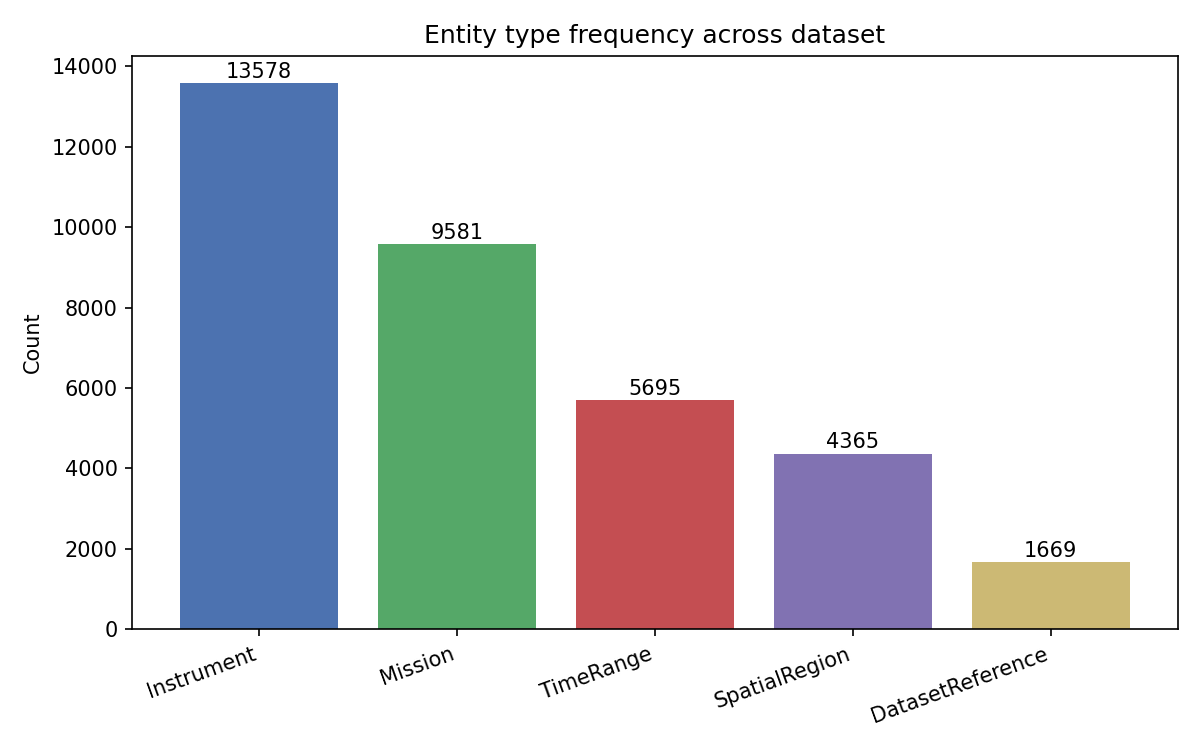

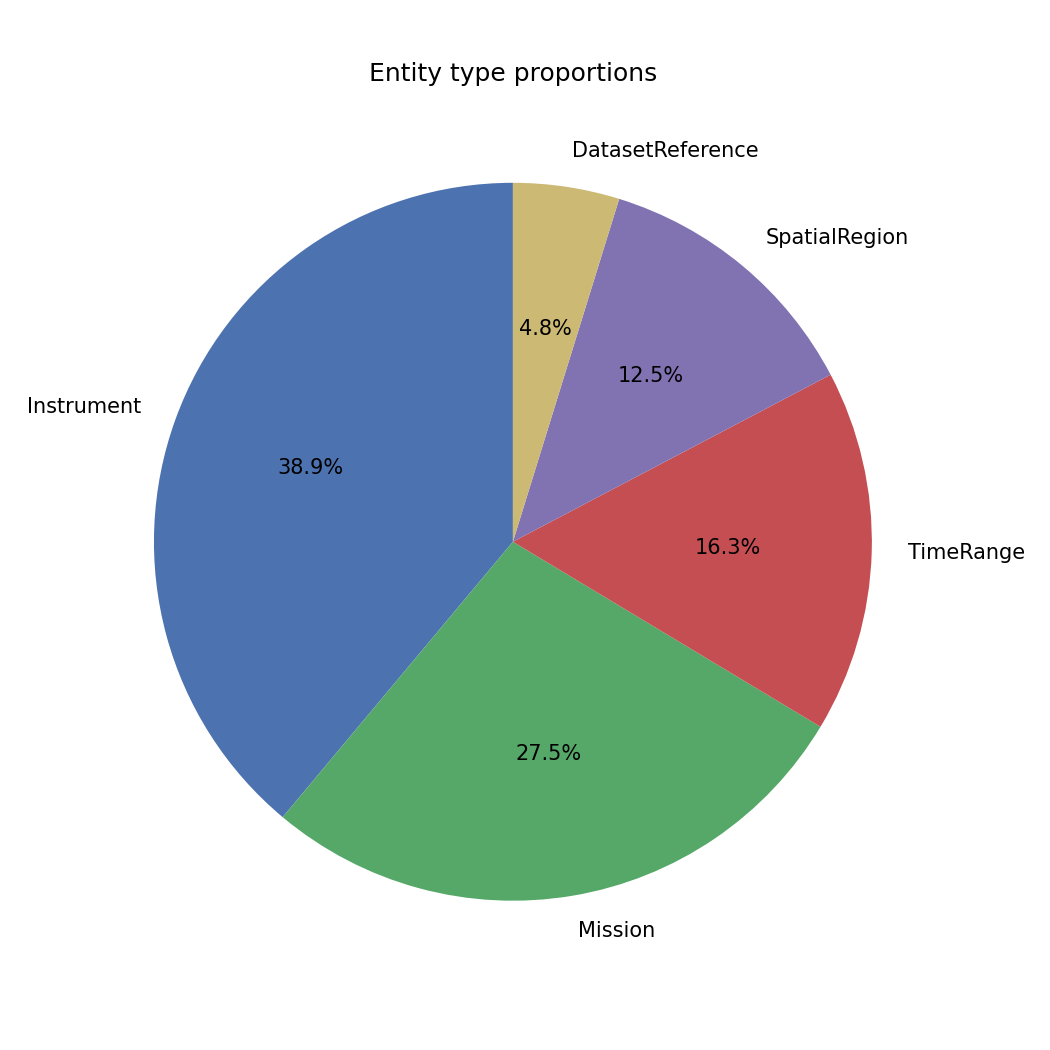

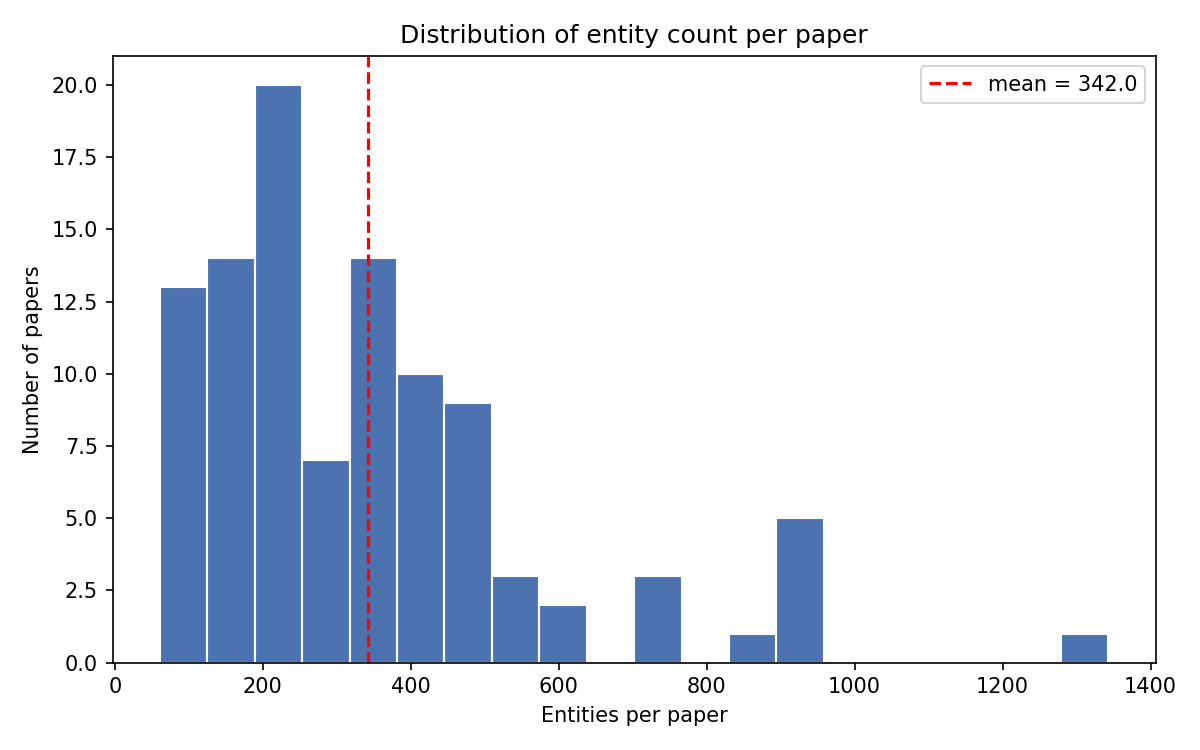

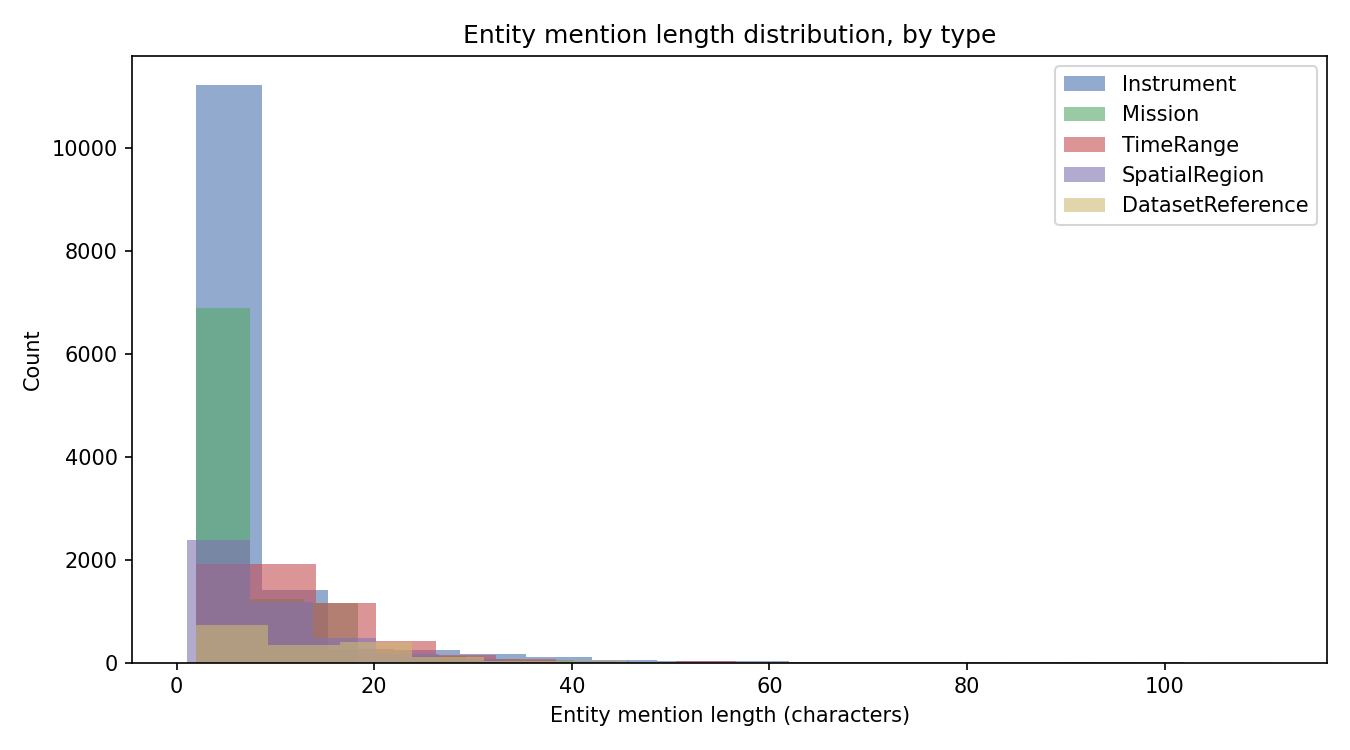

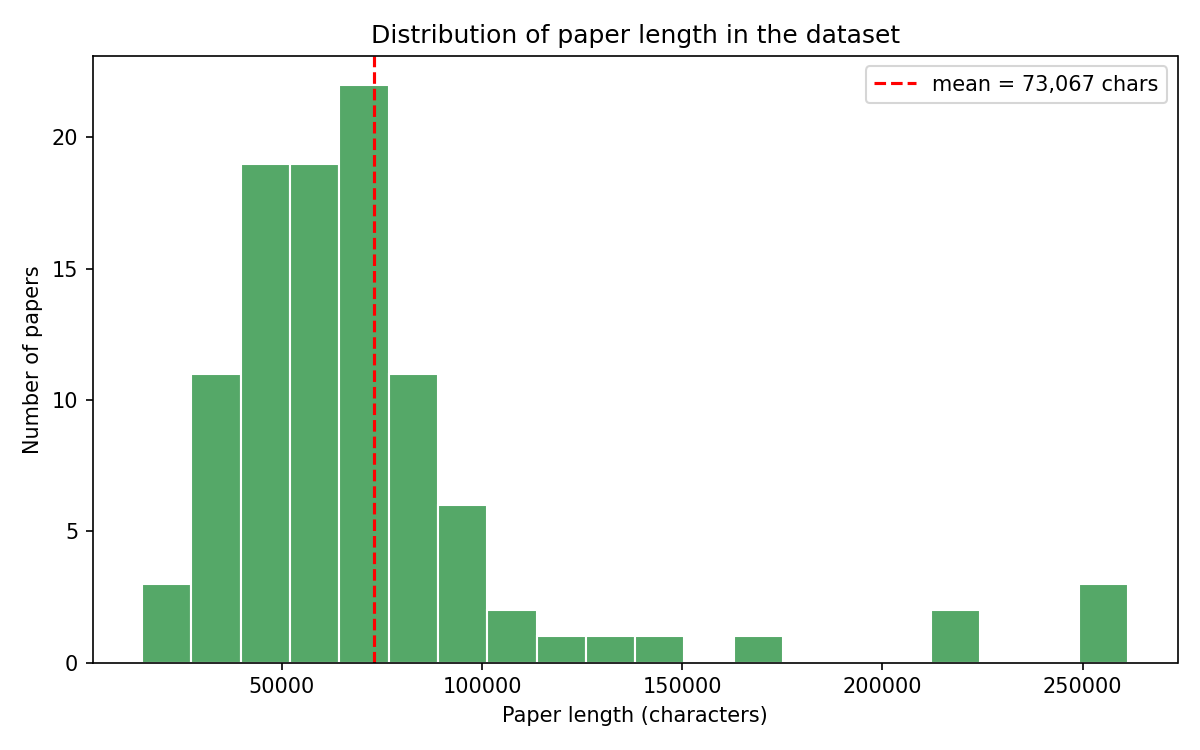

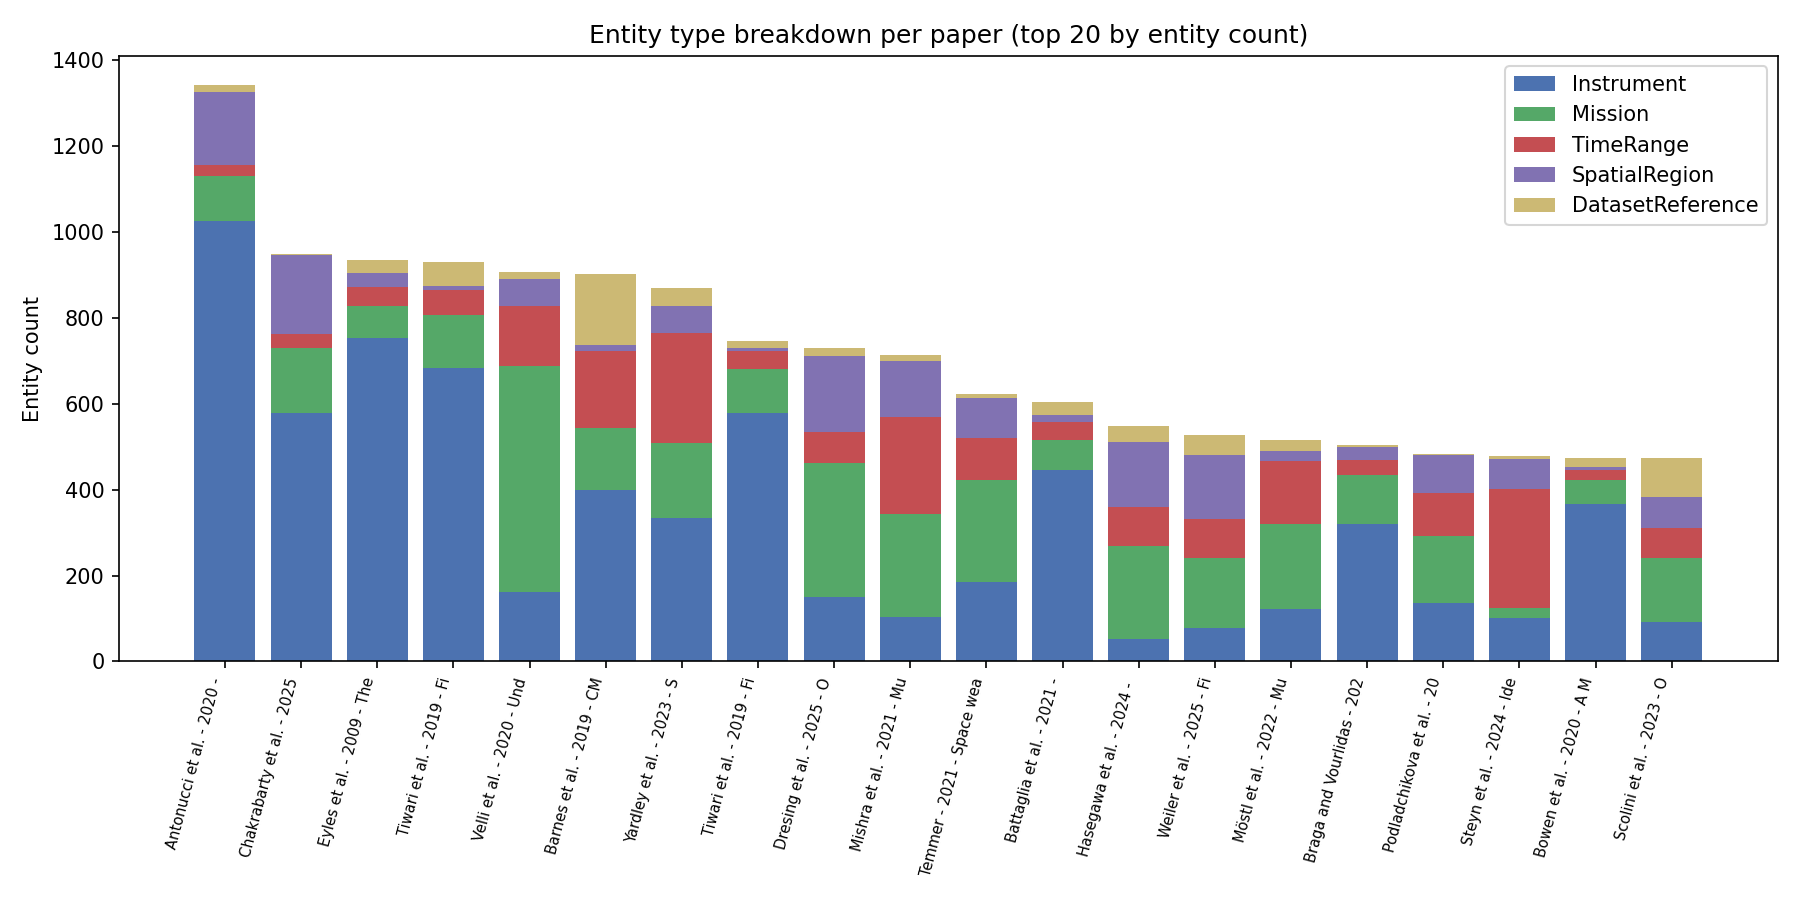

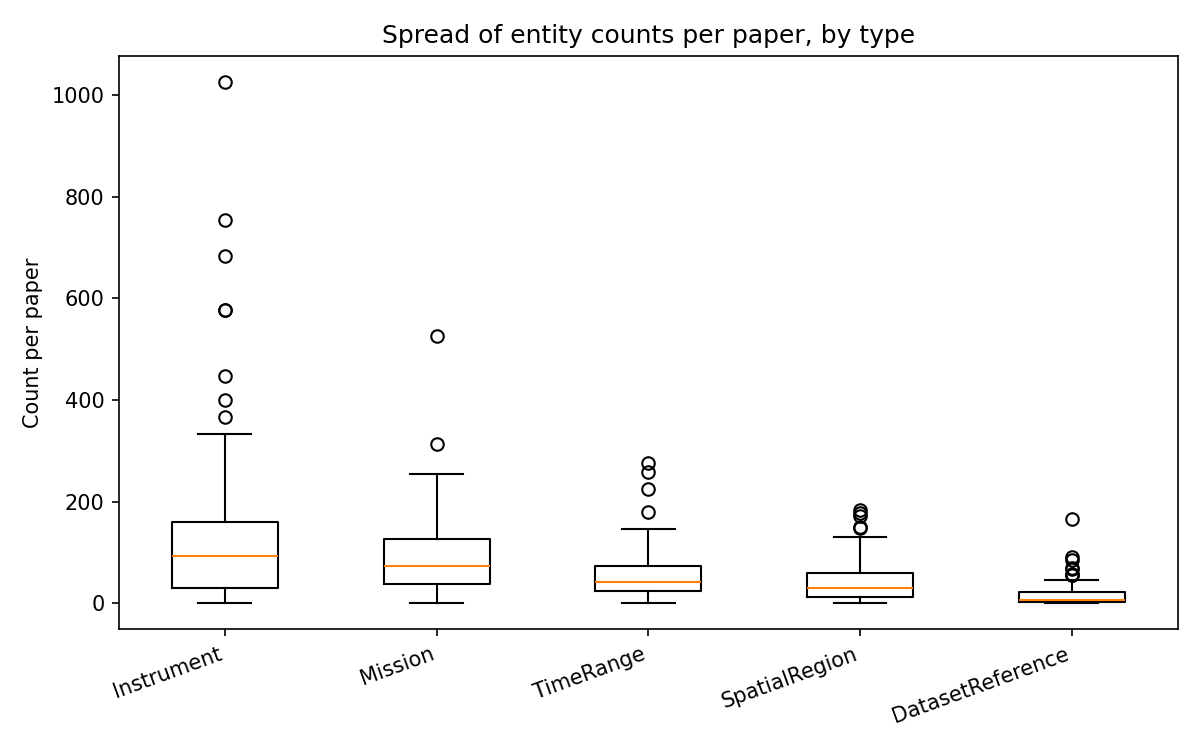

=== Dataset summary ===
Reviewed papers: 102
Total entities: 34888
Mean entities/paper: 342.0  (median: 291.5)
Mean paper length: 73,067 chars  (min: 15,124, max: 261,392)

Entity type breakdown:
  Instrument: 13578 (38.9%)
  Mission: 9581 (27.5%)
  TimeRange: 5695 (16.3%)
  SpatialRegion: 4365 (12.5%)
  DatasetReference: 1669 (4.8%)


In [ ]:
from IPython.display import Image, display

for name in [
    "01_entity_frequency_bar.png",
    "02_entity_frequency_pie.png",
    "03_entities_per_paper_hist.png",
    "04_entity_span_length_hist.png",
    "05_paper_length_hist.png",
    "06_entity_types_stacked_bar.png",
    "07_entity_count_boxplot.png",
]:
    path = OUTPUT_FOLDER / name
    if path.exists():
        display(Image(filename=str(path)))

summary_path = OUTPUT_FOLDER / "dataset_stats_summary.txt"
if summary_path.exists():
    print(summary_path.read_text())


## 6. Step 1 — Prepare the training data

In [ ]:
!python prepare_ner_dataset.py "$OUTPUT_FOLDER"


In [ ]:
report_path = OUTPUT_FOLDER / "prep_report.txt"
if report_path.exists():
    print(report_path.read_text())


## 7. Step 2 — Train the model

In [ ]:
!python train_ner_model_final.py "$OUTPUT_FOLDER"

Preview the results:

In [ ]:
from IPython.display import Image, display

for name in ["ner_precision_recall_f1.png", "ner_test_support.png", "ner_loss_curve.png"]:
    path = OUTPUT_FOLDER / name
    if path.exists():
        display(Image(filename=str(path)))

report_path = OUTPUT_FOLDER / "ner_classification_report.txt"
if report_path.exists():
    print(report_path.read_text())


                  precision    recall  f1-score   support

DatasetReference      0.369     0.528     0.434       178
      Instrument      0.695     0.838     0.760      1135
         Mission      0.861     0.919     0.889       741
   SpatialRegion      0.535     0.693     0.604       456
       TimeRange      0.679     0.776     0.724       661

       micro avg      0.679     0.806     0.737      3171
       macro avg      0.628     0.751     0.682      3171
    weighted avg      0.689     0.806     0.742      3171

